In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Linear Recurrences and Parallel Scans

The gated networks of that section can retain information over hundreds of steps, yet they still process a sequence one token after another because each step's gates and candidate depend on the previous state $\mathbf{h}_{t-1}$. On a sequence of $4{,}096$ tokens, a GRU executes $4{,}096$ sequential updates, leaving most of a GPU idle during training while a Transformer processes all positions in parallel via large matrix multiplications. Can a recurrent network retain $O(1)$-state autoregressive generation while training across all positions in parallel?

Yes—as soon as the gates and candidate depend only on the current input $\mathbf{x}_t$, making the recurrence *linear* (or more precisely, *affine*) in $\mathbf{h}_{t-1}$. Affine updates can be composed associatively just like prefix sums [@Hillis.Steele.1986], evaluating all $T$ states in $\lceil \log_2 T \rceil$ parallel rounds. Below we progress from a scalar decay to the minimal GRU (`MinGRU`) of @Feng.Tung.Ahmed.ea.2024, implement the parallel associative scan, evaluate `MinGRU` on byte-level WikiText-103, and benchmark wall-clock scaling against both sequential GRUs and causal attention up to $16{,}384$ tokens.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Linear Recurrences

### A Single Decaying Number

Start with a scalar state $h_t$ that retains a fixed fraction $a \in (0, 1)$ of its previous value and adds the input $x_t$:

$$h_t = a\, h_{t-1} + x_t, \qquad h_0 = 0.$$

Unrolling the equation expresses $h_t$ directly in terms of past inputs:

$$h_t = \sum_{s=1}^{t} a^{t-s} x_s.$$

Every $h_t$ is an exponentially weighted moving average of past inputs with half-life $\ln 2 / \ln(1/a)$ steps ($\approx 7$ steps at $a = 0.9$; $\approx 693$ steps at $a = 0.999$), and the gradient $\partial h_t / \partial x_s = a^{t-s}$ decays at the exact same rate.

### Input-Dependent Decay

Generalizing to a vector state $\mathbf{h}_t \in \mathbb{R}^d$ with input-dependent elementwise decay $\mathbf{a}_t \in (0, 1)^d$ and *write* vector $\mathbf{b}_t \in \mathbb{R}^d$ yields the affine recurrence:

$$
\mathbf{h}_t = \mathbf{a}_t \odot \mathbf{h}_{t-1} + \mathbf{b}_t,
\qquad \mathbf{a}_t = \mathbf{a}(\mathbf{x}_t), \quad
\mathbf{b}_t = \mathbf{b}(\mathbf{x}_t).
$$

Unrolling the equation replaces the power $a^{t-s}$ by the cumulative product of intermediate decays:

$$
\mathbf{h}_t = \sum_{s=1}^{t} \Big( \prod_{r=s+1}^{t} \mathbf{a}_r \Big)
\odot \mathbf{b}_s.
$$

Because $\mathbf{a}_t$ and $\mathbf{b}_t$ depend only on $\mathbf{x}_t$, all $T$ decay and write vectors can be computed in parallel across the entire sequence before the recurrence runs. And because each $\mathbf{a}_r \in (0, 1)^d$, past writes can be selectively preserved ($\mathbf{a}_r \approx \mathbf{1}$) or flushed ($\mathbf{a}_r \approx \mathbf{0}$) without ever exploding.

### The Minimal GRU

Look at the three places where the previous state $\mathbf{h}_{t-1}$ enters the standard GRU of that section:

$$
\begin{aligned}
\mathbf{z}_t &= \sigma(\mathbf{W}_{\textrm{xz}} \mathbf{x}_t + \underbrace{\mathbf{W}_{\textrm{hz}} \mathbf{h}_{t-1}}_{\textrm{(1)}} + \mathbf{b}_\textrm{z}),\\
\mathbf{r}_t &= \sigma(\mathbf{W}_{\textrm{xr}} \mathbf{x}_t + \underbrace{\mathbf{W}_{\textrm{hr}} \mathbf{h}_{t-1}}_{\textrm{(2)}} + \mathbf{b}_\textrm{r}),\\
\tilde{\mathbf{h}}_t &= \tanh\big(\mathbf{W}_{\textrm{xh}} \mathbf{x}_t + \underbrace{\mathbf{W}_{\textrm{hh}} (\mathbf{r}_t \odot \mathbf{h}_{t-1})}_{\textrm{(3)}} + \mathbf{b}_\textrm{h}\big),
\end{aligned}
$$

followed by $\mathbf{h}_t = \mathbf{z}_t \odot \mathbf{h}_{t-1} + (1 - \mathbf{z}_t) \odot \tilde{\mathbf{h}}_t$. Dropping the three marked recurrent dependencies (which eliminates the reset gate $\mathbf{r}_t$ altogether) yields the *minimal GRU* (*minGRU*) of @Feng.Tung.Ahmed.ea.2024:

$$
\begin{aligned}
\mathbf{z}_t &= \sigma(\mathbf{W}_\textrm{z} \mathbf{x}_t + \mathbf{b}_\textrm{z}), \qquad
\tilde{\mathbf{h}}_t = \tanh(\mathbf{W}_\textrm{h} \mathbf{x}_t + \mathbf{b}_\textrm{h}), \\
\mathbf{h}_t &= \mathbf{z}_t \odot \mathbf{h}_{t-1} + (1 - \mathbf{z}_t) \odot \tilde{\mathbf{h}}_t.
\end{aligned}
$$

This is an affine recurrence the equation with decay $\mathbf{a}_t = \mathbf{z}_t$ and write $\mathbf{b}_t = (1 - \mathbf{z}_t) \odot \tilde{\mathbf{h}}_t$, cutting the layer's parameter count from $6d^2$ to $2d^2$. While a single minGRU layer cannot condition its gate on what is already in $\mathbf{h}_{t-1}$, stacking multiple minGRU blocks with positionwise MLPs recovers part of that ability without sacrificing parallel evaluation across time: the gates of each layer see the states of the layer below. This gives one round of state-dependent gating per layer, where a GRU has one at every step. that section measures what a fixed number of rounds cannot do.

## Parallel Scans

### Composing Affine Steps

Evaluating the unrolled sum the equation naively for all $t = 1, \ldots, T$ would take $O(T^2)$ operations. Instead, we exploit the associativity of function composition. Represent step $t$'s affine map $\mathbf{h} \mapsto \mathbf{a}_t \odot \mathbf{h} + \mathbf{b}_t$ by the pair $(\mathbf{a}_t, \mathbf{b}_t)$. Applying step 1 followed by step 2 yields $\mathbf{a}_2 \odot (\mathbf{a}_1 \odot \mathbf{h} + \mathbf{b}_1) + \mathbf{b}_2$, which is another affine map with coefficients:

$$
(\mathbf{a}_1, \mathbf{b}_1) \bullet (\mathbf{a}_2, \mathbf{b}_2) =
(\mathbf{a}_1 \odot \mathbf{a}_2,\ \mathbf{a}_2 \odot \mathbf{b}_1 +
\mathbf{b}_2).
$$

Because function composition is associative and the composite of any block of steps is still a single $(\mathbf{a}, \mathbf{b})$ pair of the same size, computing $\mathbf{h}_1, \ldots, \mathbf{h}_T$ from $\mathbf{h}_0 = \mathbf{0}$ reduces to an associative prefix *scan* under $\bullet$ (with $\mathbf{h}_t$ read from the second component of the $t$-th prefix).

### The Doubling Schedule

the figure illustrates the parallel doubling schedule of @Hillis.Steele.1986 on $T = 8$ steps. In round $r = 0, 1, \ldots, \lceil \log_2 T \rceil - 1$, every position combines with the position at stride $2^r$ behind it. After $\lceil \log_2 T \rceil$ rounds, every position holds its complete prefix.

![A parallel scan on eight steps. Each box shows which steps its value
combines, $(1{:}4)$ meaning steps 1 to 4. In every round each position
combines with the position a fixed stride back (blue arrows), and the stride
doubles from round to round; dashed arrows copy a value unchanged. Teal
boxes hold complete prefixes. After $\log_2 8 = 3$ rounds every position
does.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-modernrnn-scan-tree.svg)

The Hillis–Steele doubling schedule performs $O(T \log_2 T)$ combines across $\lceil \log_2 T \rceil$ parallel rounds, whereas the *work-efficient* up-sweep/down-sweep tree schedule of @Blelloch.1990 performs $\sim 2T$ combines across $2\lceil \log_2 T \rceil$ shrinking rounds.

We call XLA's built-in work-efficient `jax.lax.associative_scan`.

### Implementation

`linear_scan` computes all states $\mathbf{h}_1, \ldots, \mathbf{h}_T$ of the equation along the time axis (axis 1), folding an optional initial state $\mathbf{h}_0$ into the first write $\mathbf{b}_1 \leftarrow \mathbf{a}_1 \odot \mathbf{h}_0 + \mathbf{b}_1$.

In [2]:
def linear_scan(a, b, h0=None):
    """All states of h_t = a_t * h_{t-1} + b_t; time is the second axis."""
    a = jnp.broadcast_to(a, b.shape)  # Decays may omit axes; broadcast them
    if h0 is not None:  # Fold the initial state into the first step
        b = b.at[:, 0].add(a[:, 0] * h0)
    def combine(earlier, later):
        (a1, b1), (a2, b2) = earlier, later
        return a1 * a2, a2 * b1 + b2
    # Autograd keeps the intermediate results of the scan for the backward pass
    return jax.lax.associative_scan(combine, (a, b), axis=1)[1]

Let us verify `linear_scan` against a sequential step-by-step loop on length $T = 100$ (a non-power of two).

In [3]:
def sequential_scan(a, b):
    def step(h, ab):
        h = ab[0] * h + ab[1]
        return h, h
    # lax.scan steps through the leading axis, so time goes first
    ab = (jnp.swapaxes(a, 0, 1), jnp.swapaxes(b, 0, 1))
    return jnp.swapaxes(jax.lax.scan(step, jnp.zeros_like(b[:, 0]), ab)[1], 0, 1)

key_a, key_b = jax.random.split(d2l.get_key())
a = jax.random.uniform(key_a, (4, 100, 8))
b = jax.random.normal(key_b, (4, 100, 8))
print(f'max deviation: '
      f'{jnp.abs(linear_scan(a, b) - sequential_scan(a, b)).max():.1e}')

max deviation: 4.8e-07


The parallel scan and sequential loop agree to float32 rounding tolerance ($< 10^{-6}$).

## A Linear Recurrent Language Model

### The minGRU on Text

Wrapping `linear_scan` around two linear projections ($\mathbf{W}_\textrm{z}$ and $\mathbf{W}_\textrm{h}$) implements `MinGRU` the equation as a drop-in sequence mixer for `d2l.SeqLM`.

In [4]:
class MinGRU(nnx.Module):
    """The minimal GRU: its gate and candidate read only the input."""
    def __init__(self, num_inputs, num_hiddens, *, rngs):
        self.W_z = nnx.Linear(num_inputs, num_hiddens, rngs=rngs)  # Decay
        self.W_h = nnx.Linear(num_inputs, num_hiddens, rngs=rngs)

    def coefficients(self, X):
        """Decays a_t and writes b_t of the linear recurrence."""
        Z = jax.nn.sigmoid(self.W_z(X))
        return Z, (1 - Z) * jnp.tanh(self.W_h(X))

    def __call__(self, X):  # X: (batch_size, num_steps, num_inputs)
        return linear_scan(*self.coefficients(X))

How much modeling quality does dropping $\mathbf{h}_{t-1}$ from the gates cost on byte-level WikiText-103? Using the exact setup of that section (4 blocks of `d2l.SeqLM`, 128-byte windows, 1,000 steps), we first define `text_model` and the three comparison `arms`: `GRU` ($d = 256$, $3.81\textrm{M}$ parameters), `minGRU` at equal width ($d = 256$, $2.76\textrm{M}$ parameters), and `minGRU` widened to equal parameter count (`minGRU, d=302`, $3.81\textrm{M}$ parameters):

In [5]:
def text_model(mixer, d):  # 256 byte values; four blocks of width d
    rngs = nnx.Rngs(d2l.get_key())
    return d2l.SeqLM(256, d, [mixer(d, rngs) for _ in range(4)], rngs=rngs)

lecun = nnx.initializers.lecun_normal()  # For the recurrent matrices
gru = lambda d, rngs: nnx.RNN(
    nnx.GRUCell(d, d, recurrent_kernel_init=lecun, rngs=rngs), unroll=8)
min_gru = lambda d, rngs: MinGRU(d, d, rngs=rngs)
arms = {'GRU': (gru, 256), 'minGRU': (min_gru, 256),
        'minGRU, d=302': (min_gru, 302)}  # As many parameters as the GRU

We load the 128-byte `WikiText103` dataset, run `d2l.text_table` across all three arms, and retain the first trained `minGRU` model for inspection:

In [6]:
data = d2l.WikiText103(batch_size=64, num_steps=128)
trained = d2l.text_table(text_model, arms, data)
model = trained['minGRU'][0]  # The model we look inside below

                           validation        0-15       16-63      64-127   ms/step


GRU             3,814,144 1.299/1.297 1.490/1.490 1.273/1.272 1.271/1.268 16/16


minGRU          2,764,544 1.341/1.346 1.518/1.520 1.317/1.321 1.316/1.321 10/10


minGRU, d=302   3,816,932 1.329/1.330 1.510/1.509 1.304/1.306 1.302/1.304 10/10


At equal width ($d = 256$), `minGRU` finishes $\sim 0.05$ nats/byte behind `GRU` ($1.35$ vs. $1.30$), and at equal parameter count (`minGRU, d=302`) it closes about two fifths of the gap ($\sim 1.33$), landing right alongside the plain $\tanh$ RNN of that section while beating the attention baseline ($1.38$) and training via a parallel scan rather than a sequential loop.

### Inside the Trained Model

To check how much `minGRU` relies on its recurrent state, we evaluate the trained $d = 256$ model with its state zeroed before every step (`StateReset`, so $\mathbf{h}_t = \mathbf{b}_t$ depends only on the current byte).

In [7]:
class StateReset(nnx.Module):
    """A minGRU layer whose state is reset to zero before every step."""
    def __init__(self, layer):
        self.layer = layer

    def __call__(self, X):
        return self.layer.coefficients(X)[1]

layers = model.mixers
loss = np.mean(d2l.loss_by_position(model, data))
model.mixers = nnx.List([StateReset(layer) for layer in layers])
reset = np.mean(d2l.loss_by_position(model, data))
model.mixers = layers
print(f'validation loss: {loss:.3f} nats per byte, '
      f'with the state reset at every step: {reset:.3f}')

validation loss: 1.341 nats per byte, with the state reset at every step: 2.481


Zeroing the state raises validation loss from $1.35$ to $2.48$ nats/byte (essentially the $2.45$ nats/byte empirical byte-bigram baseline of that section), confirming that over $1.1$ nats/byte comes from context carried in the state.

We can also inspect the distribution of update-gate decays $\mathbf{z}_t$ in the first block before and after training. Adding `first_mixer_input` to `d2l.SeqLM` lets us extract the normalized token embeddings fed to the first mixer.

In [8]:
@d2l.add_to_class(d2l.SeqLM)
def first_mixer_input(self, X):
    """What the first mixer reads: the normalized token embeddings."""
    return self.norms[0](self.embedding(X))

Passing a validation minibatch through `first_gates` on both an untrained `minGRU` and our trained `model` tabulates the fraction of update gates exceeding $0.5$, $0.9$, and $0.99$:

In [9]:
def first_gates(model, X):  # Gates of the first layer
    return model.mixers[0].coefficients(model.first_mixer_input(X))[0]

X = jnp.asarray(next(iter(data.val_dataloader()))[0])  # Validation text
Z_init = first_gates(text_model(min_gru, 256), X)  # Untrained
Z = first_gates(model, X)
print('gate above  half-life in steps  share at initialization  trained')
for g in (0.5, 0.9, 0.99):
    print(f'{g:10}  {math.log(2) / -math.log(g):17.0f}  '
          f'{(Z_init > g).mean():23.1%}  {(Z > g).mean():7.1%}')

gate above  half-life in steps  share at initialization  trained
       0.5                  1                    49.5%    52.0%


       0.9                  7                     1.1%    18.2%
      0.99                 69                     0.0%     0.1%


Training increases the share of gates with half-life $\ge 7$ bytes ($g > 0.9$) more than tenfold (from $\sim 1\%$ to about $18\%$), matching the word-level timescales needed over 128-byte windows, while almost no gates reach $g > 0.99$ (half-life 69 bytes) from zero-bias initialization.

## Cost against Attention

### Work, Depth, and Memory

the table compares the asymptotic training work, sequential depth, and autoregressive generation state of one layer of width $d$ across $T$ tokens.

<!-- tbl-caption:Cost of one layer of width $d$ on $T$ tokens, up to constant factors. -->

| Layer | Training work | Steps in a row | Memory at generation |
| :-- | :-- | :-- | :-- |
| GRU, one step at a time | $T d^2$ | $T$ | $d$ |
| minGRU, doubling scan | $T d^2 + T d \log_2 T$ | $\log_2 T$ | $d$ |
| minGRU, work-efficient scan | $T d^2 + T d$ | $2 \log_2 T$ | $d$ |
| Causal attention | $T d^2 + T^2 d$ | a few matrix products | $2 T d$ |

Both `GRU` and `minGRU` perform $O(Td^2)$ projection work and carry an $O(d)$ state vector during decoding, but `minGRU` reduces sequential training depth from $T$ matrix-vector steps to $O(\log_2 T)$ elementwise scan rounds. Causal attention has $O(1)$ sequential depth during training, but its attention score and mixing work grows quadratically as $O(T^2 d)$ (crossing its $8Td^2$ projection FLOPs around $T \approx 4d$) and its inference KV cache grows linearly as $2Td$.

### Measured Cost

To see where these scaling laws cross on real hardware, we time a forward-plus-backward pass in float16 at width $d = 256$ keeping the total token count per batch fixed at $B \times T = 65{,}536$ as sequence length $T$ sweeps from $512$ to $16{,}384$. With total tokens fixed, any layer whose cost is strictly linear in $T$ will have a flat curve, while a layer dominated by $O(T)$ sequential steps or $O(T^2)$ pairwise work will double its runtime each time $T$ doubles.

In [10]:
class FusedAttention(d2l.CausalAttention):
    """Causal attention through cuDNN's fused kernel."""
    @staticmethod
    def attend(q, k, v):
        return jax.nn.dot_product_attention(q, k, v, is_causal=True,
                                            implementation='cudnn')

d, tokens = 256, 65536  # Width; tokens per call, in sequences of length T
half, rngs = jnp.float16, nnx.Rngs(d2l.get_key())  # 16-bit floats
timed = {'GRU': nnx.RNN(nnx.GRUCell(d, d, recurrent_kernel_init=lecun,
                                    param_dtype=half, rngs=rngs), unroll=8),
         'minGRU': MinGRU(d, d, rngs=rngs),
         'attention': FusedAttention(d, num_heads=4, rngs=rngs)}
for layer in timed.values():  # Every weight in 16 bits
    params = nnx.state(layer, nnx.Param)
    nnx.update(layer, jax.tree.map(lambda p: p.astype(half), params))

@nnx.jit
def forward_backward(layer, X):
    loss = lambda layer, X: layer(X).astype(jnp.float32).sum()
    return nnx.grad(loss, argnums=(0, 1))(layer, X)

def time_call(layer, T):
    """Milliseconds for a forward and backward pass over tokens / T
    sequences of length T."""
    X = jax.random.normal(d2l.get_key(), (tokens // T, T, d), half)
    return 1000 * d2l.Benchmark(lambda: forward_backward(layer, X),
                                warmup=1, repeats=3).time

Sweeping `time_call` across sequence lengths $T \in \{512, 1024, 2048, 4096, 8192, 16384\}$ compares the wall-clock runtime of `GRU`, `minGRU`, and `attention` on log–log axes:

T             512    1024    2048    4096    8192   16384
GRU          11.2    18.7    34.0    55.5    98.0   203.3
minGRU        1.1     1.3     1.2     1.2     1.3     1.2
attention     2.9     3.0     3.9     6.0    10.1    17.1


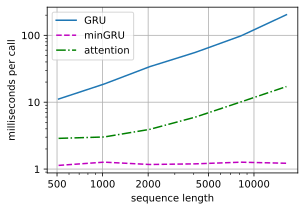

In [11]:
lengths = [512, 1024, 2048, 4096, 8192, 16384]
times = {name: [time_call(layer, T) for T in lengths]
         for name, layer in timed.items()}
print('T        ', *(f'{T:>7d}' for T in lengths))
for name, ms in times.items():
    print(f'{name:9s}', *(f'{t:7.1f}' for t in ms))
d2l.plot(lengths, list(times.values()), 'sequence length',
         'milliseconds per call', legend=list(times), xscale='log',
         yscale='log', figsize=(4.5, 3))

The empirical scaling curves match the table:

- **`GRU`:** slowest at every length, growing more than $15\times$ from $T = 512$ to $16{,}384$ because its $T$ sequential steps cannot be parallelized across time.
- **`minGRU`:** nearly flat across the entire 32-fold increase in sequence length.
- **`attention`:** nearly flat up to $T \approx 2{,}048$ where $O(Td^2)$ projections and memory traffic dominate, then bending upward toward $2\times$ per doubling once the $O(T^2 d)$ attention term takes over.

The work-efficient scan of `minGRU` stays flat and is faster than `attention` at every length, about $14\times$ at $T = 16{,}384$.

What `minGRU` still lacks is a structured way to initialize and control multi-timescale memories—the question that section addresses via continuous-time state space models.

## Summary

Removing the previous state $\mathbf{h}_{t-1}$ from a recurrent layer's gates yields an affine recurrence $\mathbf{h}_t = \mathbf{a}_t \odot \mathbf{h}_{t-1} + \mathbf{b}_t$ whose steps compose associatively via $(\mathbf{a}_1, \mathbf{b}_1) \bullet (\mathbf{a}_2, \mathbf{b}_2) = (\mathbf{a}_1 \odot \mathbf{a}_2, \mathbf{a}_2 \odot \mathbf{b}_1 + \mathbf{b}_2)$. An associative scan evaluates all $T$ states in $O(\log_2 T)$ parallel rounds during training while preserving $O(1)$-state sequential updates during decoding. Applied to the GRU, this simplification produces `MinGRU`, which matches a parameter-matched plain RNN on byte-level WikiText-103 (about $0.03$ nats/byte behind a full GRU) while training at nearly constant per-token time up to $16{,}384$ tokens—over an order of magnitude faster than a sequential GRU and several times faster than quadratic attention at long contexts.

## Exercises

1. **Closure under composition.** A parallel scan needs more than
   associativity: the composite of any run of steps must be described by as
   many numbers as a single step, so that every combine costs the same.
    1. Generalize the equation to the recurrence
       $\mathbf{h}_t = \mathbf{A}_t \mathbf{h}_{t-1} + \mathbf{b}_t$ with
       dense matrices $\mathbf{A}_t \in \mathbb{R}^{d \times d}$, keeping
       the factors of each product in the right order. Count the
       multiply-adds of one combine and of one sequential step. Compare the
       total work of the doubling scan, about $T \log_2 T$ combines, with
       that of the loop at $T = 4096$ and $d = 64$. What does the
       comparison suggest about dense transition matrices?
    1. For the scalar step $h \mapsto \tanh(w_t h + c_t)$, show that the
       composite of two steps with $w_1, w_2 \neq 0$ is not of the form
       $h \mapsto \tanh(w h + c)$ for any $w$ and $c$. What would a scan
       have to store to represent the composite of $k$ steps?

1. [code] **The direct route.** For scalar decays, the unrolled sum
   the equation can be evaluated without a scan, from
   cumulative products $P_t = a_1 a_2 \cdots a_t$ and one cumulative sum.
    1. Show that $h_t = P_t \sum_{s=1}^{t} b_s / P_s$. Implement it with a
       library `cumprod` and `cumsum` and compare it with `linear_scan` in
       32-bit floats on decays drawn near 0.9. At what length does it fail,
       and why does the scan not fail there?
    1. @Feng.Tung.Ahmed.ea.2024 repair the formula by working with
       logarithms of the decays and of the writes, replacing the sum by a
       cumulative log-sum-exp. Implement the repair. What does it require
       of the signs of the writes, and how do the authors arrange it?

1. [code] **Candidate nonlinearity.** `MinGRU` keeps a $\tanh$ on the
   candidate $\tilde{\mathbf{h}}_t$, whereas
   @Feng.Tung.Ahmed.ea.2024 use a linear candidate.
    1. Starting from $\mathbf{h}_0 = \mathbf{0}$, write each coordinate of
       $\mathbf{h}_t$ as a weighted sum of the candidates
       $\tilde{\mathbf{h}}_1, \ldots, \tilde{\mathbf{h}}_t$. Show that the
       weights are nonnegative and sum to at most one, and derive a bound on
       $|\mathbf{h}_t|$ that holds at every length, with and without the
       $\tanh$.
    1. Remove the $\tanh$, train the language model of this section twice
       with `d2l.train_text`, and compare its validation loss with the two
       runs of `MinGRU`. Is the difference larger than the spread between
       runs? Relate what you observe to your bound.

1. [code] **State passing.** `linear_scan` accepts an initial state, so a
   long sequence can be processed in pieces.
    1. Split a sequence of length $T$ into chunks of length $\tau$, run the
       scan on each chunk starting from the final state of the previous
       one, and check that the concatenated states match a single call on
       the whole sequence.
    1. Now stop gradients through the carried state at every chunk
       boundary. The states do not change. Which contributions to the
       gradient of the loss at step $t$ disappear, and which dependencies
       can the trained model still use when it generates text? Compare with
       truncated backpropagation through time (that section).

1. [code] **Work-efficient scans.** ● A recursive schedule does less work
   than the doubling schedule: combine adjacent pairs, which halves the
   sequence; scan the half-length sequence recursively, which yields every
   second prefix; then obtain each remaining prefix with one more combine.
    1. For $T = 2^k$, count the combines and the rounds of combines of each
       schedule, and compare both with the $T - 1$ steps of the loop at
       $T = 16384$.
    1. Implement both schedules with slicing, check both against
       `sequential_scan`, and time them at the lengths of the measurement
       in that section. Does the ratio of times
       follow the ratio of combines? Explain why it might not at short
       lengths.

[Discussions](https://d2l.discourse.group/t/36885)